# Batch API

**이 노트북에서 할 일**

1. 문의 글 다섯으로 일괄 처리(Batch API) 입력 파일을 만들어, 운영체제 임시 폴더에 씁니다.
2. 노트북 밖에서 한 번 맡긴 일괄 작업의 결과 파일과 오류 파일을 읽고, 예상 비용을 어림합니다.
3. 결과 줄을 입력 차례대로 짝짓는 방법(Before)과 요청 이름표로 짝짓는 방법(After)을 견줍니다.

**준비물** — 이 노트북은 모델에 요청을 보내지 않고, API 키도 쓰지 않습니다.
일괄 작업은 교재를 만들 때 노트북 밖에서 한 번 맡겼습니다.
노트북은 그 작업에서 받은 파일을 실습 폴더 `data/`에서 읽기만 합니다.
받은 파일에서 작업·파일·요청마다 붙는 ID와 시각은 빼고 두었습니다.

입력 파일은 운영체제 임시 폴더에만 쓰고, 실습 폴더에는 파일을 쓰지 않습니다.
실습 폴더의 도구 파일 `cost_tools.py`에서 함수 다섯을 가져옵니다.
따로 설치할 패키지는 없습니다. 걸린 시간은 재지 않았습니다.

**기준 버전** — 이 노트북은 Python에 들어 있는 모듈과 도구 파일만 씁니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 버전과 Windows·macOS에서는 실행하지 않았습니다.

**강의와 실습 범위** — 강의 시간에는 3절에서 결과 파일과 오류 파일을 함께 읽습니다.
입력 파일을 만드는 2절, 비용을 셈하는 4절, 두 방법을 견주는 5·6절은 실습 시간에 실행합니다.

실습 폴더 `labs/part7/ch34-cost-rate-limits`에서 `uv sync --locked`를 실행합니다.
그다음 `notebooks/` 폴더의 이 노트북을 열고, 실습 폴더의 `.venv` 커널을 고릅니다.
첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

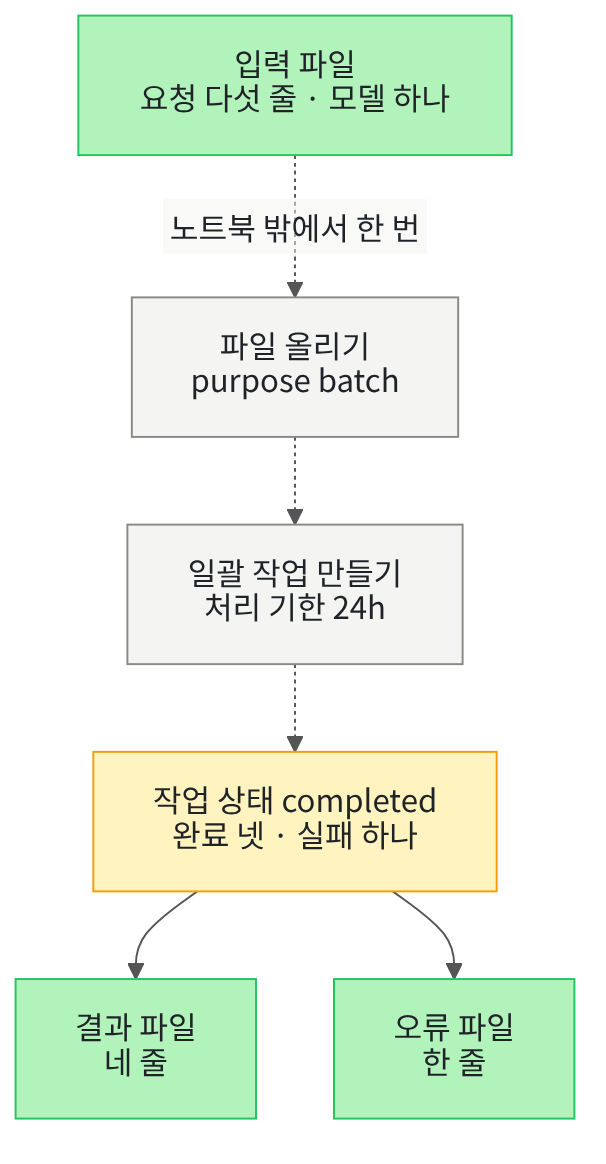

위에서 아래로 읽습니다.
점선과 회색 상자는 교재를 만들 때 노트북 밖에서 한 번 한 단계이고, 노트북에서는 실행하지 않습니다.
노란 상자는 노트북 3절에서 출력한 작업 기록이고, 초록 상자는 노트북이 만든 입력 파일과 읽는 자료 파일입니다.

## 1. 준비

제목의 Batch API는, 곧바로 답이 필요 없는 요청을 파일로 모아 맡기고 결과를 나중에 받는 방법입니다.
Ch 15 08절은 이 방법을 일괄 처리(Batch API)라고 불렀고, 이 절도 그 말을 씁니다.
Ch 15 08절은 입력 파일까지만 만들고 맡기지는 않았습니다.
이 절은 맡긴 뒤에 받는 파일을 읽습니다.

첫 셀은 이 절에서 쓸 모듈과 도구 파일의 함수를 가져옵니다.
따로 설치할 패키지가 없어, 설치 셀은 두지 않았습니다.

In [1]:
# 파일 위치 찾기·임시 폴더·JSON 글에 쓸 모듈과, 도구 파일의 함수 다섯을 가져옵니다
import json
import os
import tempfile
# Ch 6 06절과 Ch 15 08절에서 배운 함수는 도구 파일에서 가져옵니다
from cost_tools import estimate_cost, make_batch_line, write_jsonl, read_jsonl, ids_not_in

print("가져온 모듈:", "json, os, tempfile")
print("도구 파일에서 가져온 함수:", estimate_cost.__name__, make_batch_line.__name__, write_jsonl.__name__)
print("도구 파일에서 가져온 함수:", read_jsonl.__name__, ids_not_in.__name__)

가져온 모듈: json, os, tempfile
도구 파일에서 가져온 함수: estimate_cost make_batch_line write_jsonl
도구 파일에서 가져온 함수: read_jsonl ids_not_in


**결과 읽기** — 출력 줄 `가져온 모듈: json, os, tempfile`이 보입니다.
세 모듈은 Python에 들어 있어 따로 설치하지 않습니다.
함수 `estimate_cost`는 01절처럼 Ch 6 06절에서 배운 함수입니다.
나머지 넷은 Ch 15 08절에서 배웠고, 이 절에서 도구 파일에 옮겼습니다.

앞에서 배운 함수는 `cost_tools.py`에 모아 두었습니다.
파일을 열면 코드를 볼 수 있습니다.
노트북과 같은 폴더(`notebooks/`)에 있는 파일입니다.
커널이 `notebooks/` 폴더에서 시작해야 이 파일을 가져올 수 있습니다.
교재 출력을 만든 실행 도구는 이 폴더를 따로 알려 주어, 다른 자리에서 시작해도 가져오기가 되었습니다.

다음 셀은 실습 폴더의 위치를 찾습니다.
이 절은 실습 폴더 `data/`의 자료 파일 셋을 읽기 때문입니다.

In [2]:
# 노트북을 연 자리에서 본 실습 폴더의 위치를 후보 셋 가운데에서 고릅니다
candidates = ["..", ".", "labs/part7/ch34-cost-rate-limits"]
lab_path = None
for candidate in candidates:
    if os.path.exists(candidate + "/data/batch-output.jsonl"):
        lab_path = candidate
        break
print("실습 폴더를 찾았는가:", lab_path is not None)
assert lab_path is not None, "notebooks 폴더나 실습 폴더 맨 위에서 노트북을 열어 주세요."

실습 폴더를 찾았는가: True


**결과 읽기** — 출력 줄 `실습 폴더를 찾았는가: True`가 보입니다.
첫 후보 `..`는 `notebooks/` 폴더에서 열었을 때 맞는 자리입니다.
둘째 `.`는 실습 폴더 맨 위, 셋째는 프로젝트 맨 위에서 열었을 때 맞습니다.
고른 후보는 연 자리마다 달라서 출력하지 않습니다.

## 2. 입력 파일 만들기

일괄 처리의 입력 파일은 요청 하나를 JSON 한 줄로 적은 JSONL 파일입니다.
Ch 15 08절에서 배운 대로, 한 줄에는 네 칸 `custom_id`·`method`·`url`·`body`가 들어갑니다.
이 절은 01절의 문의 분류를 요청 다섯 줄로 만들어 봅니다.

다음 셀은 일괄 처리로 맡길 문의 글 다섯을 목록에 담습니다.
첫째와 셋째는 01절의 문의 글 둘이고, 셋을 더했습니다.

In [3]:
# 일괄 처리로 맡길 문의 글 다섯을 목록에 담습니다(첫째·셋째는 01절의 문의 글입니다)
inquiries = [
    "주문한 책이 일주일째 오지 않습니다. 이 문의의 종류를 배송, 환불, 결제 가운데 한 낱말로 답하세요.",
    "결제 창에서 카드 번호를 넣었는데 다음 단계로 넘어가지 않습니다. 이 문의의 종류를 배송, 환불, 결제 가운데 한 낱말로 답하세요.",
    "받은 책이 찢어져 있어 돈을 되찾고 싶습니다. 이 문의의 종류를 배송, 환불, 결제 가운데 한 낱말로 답하세요.",
    "주문한 책을 받을 주소를 회사로 바꾸고 싶습니다. 이 문의의 종류를 배송, 환불, 결제 가운데 한 낱말로 답하세요.",
    "결제 수단을 카드에서 계좌 이체로 바꿀 수 있나요? 이 문의의 종류를 배송, 환불, 결제 가운데 한 낱말로 답하세요.",
]
print("문의 글 수:", len(inquiries))

문의 글 수: 5


**결과 읽기** — 출력 줄 `문의 글 수: 5`가 보입니다.
다섯 문의는 차례대로 배송, 결제, 환불, 배송, 결제를 묻는 글입니다.
이웃한 두 문의가 묻는 종류는 모두 다릅니다.
그래서 답이 한 칸씩 밀리면, 문의와 답이 맞지 않는 것이 눈에 보입니다.

다음 셀은 요청마다 붙일 요청 이름표를 적습니다.
요청 이름표(custom_id)는 입력 파일의 요청 한 줄마다 붙이는 겹치지 않는 이름입니다.
외투를 맡길 때 받는 보관표처럼, 나중에 결과를 찾을 때 이 이름을 봅니다.
이 절 코드에서는 `inquiry-1`부터 `inquiry-5`까지가 요청 이름표입니다.

In [4]:
# 요청마다 붙일 요청 이름표 다섯을, 문의 글과 같은 차례로 적습니다
request_names = ["inquiry-1", "inquiry-2", "inquiry-3", "inquiry-4", "inquiry-5"]
print("요청 이름표:", request_names)

요청 이름표: ['inquiry-1', 'inquiry-2', 'inquiry-3', 'inquiry-4', 'inquiry-5']


**결과 읽기** — 라벨 `요청 이름표:` 뒤에 이름표 다섯이 문의 글과 같은 차례로 있습니다.
공식 안내는 한 작업 안에서 요청 이름표가 겹치면 안 된다고 적습니다.
다섯 이름표는 끝 번호가 모두 달라 겹치지 않습니다.
Ch 15 08절은 같은 칸에 판 표시와 질문 번호를 이어 붙인 이름을 썼습니다.

다음 셀은 요청 주소와, 요청 본문에 넣을 모델 설정을 정합니다.
Ch 15 08절처럼 과정의 모델 설정을 본문의 같은 이름 칸에 적습니다.

In [5]:
# 요청 주소와, 요청 본문에 넣을 과정 표준 모델 설정을 정합니다(Ch 15 08절과 같은 값입니다)
url = "/v1/chat/completions"
settings = {"model": "gpt-5.4-mini", "temperature": 0, "reasoning_effort": "none"}
print("요청 주소:", url)
print("모델 설정:", settings)

요청 주소: /v1/chat/completions
모델 설정: {'model': 'gpt-5.4-mini', 'temperature': 0, 'reasoning_effort': 'none'}


**결과 읽기** — 출력 줄 `요청 주소: /v1/chat/completions`가 보입니다.
Ch 15 08절에서 본 대로, 이 과정의 LangChain 모델 객체도 이 요청 주소로 요청을 보냅니다.
모델 설정에는 `'temperature': 0`과 `'reasoning_effort': 'none'`이 있습니다.
공식 안내는 한 입력 파일에 모델 하나의 요청만 담으라고 적어, 다섯 줄 모두 같은 모델로 둡니다.

다음 셀은 둘째 문의에만 쓸 설정을 따로 만듭니다.
둘째 문의는 결제 창이 넘어가지 않는다는 글이라, 모델이 조금 더 생각하게 하고 싶다고 해 봅니다.
그래서 인자 `reasoning_effort`만 low로 바꾸고, temperature 0은 그대로 둡니다.
메서드 `copy`는 딕셔너리를 하나 더 만들어, 원래 설정은 바뀌지 않습니다.

이 설정은 공식 안내대로면 거절될 줄로, 교재를 만들 때 골랐습니다.
결과 파일이 입력보다 짧아지는 경우를 보려는 것입니다.

In [6]:
# 둘째 문의에만 쓸 설정을 만듭니다: 생각하는 단계를 조금 쓰게 low로 바꾸고, temperature 0은 그대로 둡니다
thinking_settings = settings.copy()
thinking_settings["reasoning_effort"] = "low"
print("둘째 문의의 설정:", thinking_settings)

둘째 문의의 설정: {'model': 'gpt-5.4-mini', 'temperature': 0, 'reasoning_effort': 'low'}


**결과 읽기** — 출력 줄 끝이 `'reasoning_effort': 'low'}`입니다.
원래 설정과 달라진 칸은 이것 하나이고, 온도 칸은 `'temperature': 0` 그대로입니다.
공식 GPT-5.4 안내는 온도 칸을 생각하는 단계가 none일 때만 받는다고 적습니다.
다른 단계와 함께 온도 칸을 보내면 오류가 난다고도 적습니다.
이 줄이 실제로 어떻게 되었는지는 3절에서 받은 파일로 봅니다.

다음 셀은 문의마다 요청 한 줄을 만듭니다.
함수 `make_batch_line`은 Ch 15 08절처럼, 설정 딕셔너리를 복사하고 사용자 메시지 하나를 더해 요청 한 줄을 만듭니다.
이름표가 `inquiry-2`인 줄에만 바꾼 설정을 넣습니다.

In [7]:
# 문의마다 요청 한 줄을 만듭니다(이름표 inquiry-2 줄만 바꾼 설정을 씁니다)
batch_lines = []
for number in range(len(inquiries)):
    line_settings = settings
    if request_names[number] == "inquiry-2":
        line_settings = thinking_settings
    batch_lines.append(make_batch_line(request_names[number], url, line_settings, inquiries[number]))
print("만든 요청 줄 수:", len(batch_lines))
print("둘째 줄의 요청 본문 설정:", batch_lines[1]["body"]["reasoning_effort"], batch_lines[1]["body"]["temperature"])

만든 요청 줄 수: 5
둘째 줄의 요청 본문 설정: low 0


**결과 읽기** — 출력 줄 `만든 요청 줄 수: 5`가 보입니다.
둘째 줄의 본문 설정은 `low 0`으로, 생각하는 단계 low와 temperature 0입니다.
나머지 네 줄은 과정 표준 설정을 그대로 씁니다.
다섯 줄의 모델은 모두 같아, 한 파일에 한 모델만 담는다는 안내를 지킵니다.

다음 셀은 운영체제 임시 폴더에 새 폴더를 만들고, 다섯 줄을 입력 파일로 씁니다.
함수 `tempfile.mkdtemp`는 임시 폴더 안에 새 폴더를 만들고, 그 위치를 글로 내놓습니다.
Ch 23에서처럼 새 파일은 실습 폴더가 아니라 임시 폴더에 씁니다.
함수 `write_jsonl`과 `read_jsonl`은 Ch 15 08절에서 파일을 쓰고 다시 읽을 때 쓴 함수입니다.

In [8]:
# 운영체제 임시 폴더에 새 폴더를 만들고, 요청 다섯 줄을 입력 파일로 씁니다(실습 폴더에는 쓰지 않습니다)
input_folder = tempfile.mkdtemp(prefix="ch34-02-")
input_path = os.path.join(input_folder, "batch-input.jsonl")
write_jsonl(input_path, batch_lines)
input_rows = read_jsonl(input_path)
print("다시 읽은 줄 수:", len(input_rows))
print("쓴 목록과 다시 읽은 목록이 같은가:", input_rows == batch_lines)
print("입력 파일의 크기(바이트):", os.path.getsize(input_path))

다시 읽은 줄 수: 5
쓴 목록과 다시 읽은 목록이 같은가: True
입력 파일의 크기(바이트): 1780


**결과 읽기** — 출력 줄 `다시 읽은 줄 수: 5`와 `쓴 목록과 다시 읽은 목록이 같은가: True`가 보입니다.
입력 파일의 크기는 `1780`바이트입니다.
교재를 만들 때 노트북 밖에서 맡긴 입력 파일도 이 셀까지의 코드로 만들었고, 바이트까지 같았습니다.
임시 폴더의 위치는 실행마다 달라서 출력하지 않습니다.
임시 폴더의 파일은 실습 폴더 밖에 있어 그대로 둡니다.

다음 셀은 입력 파일 둘째 줄의 칸 이름과, 그 줄을 JSON 글로 바꾼 모습을 봅니다.
함수 `json.dumps`에 인자 `ensure_ascii=False`를 주면 한글을 그대로 적습니다.

In [9]:
# 입력 파일 둘째 줄의 칸 이름과, 그 줄을 JSON 글로 바꾼 모습을 봅니다
second_line = input_rows[1]
second_text = json.dumps(second_line, ensure_ascii=False)
print("둘째 줄의 칸:", list(second_line))
print("둘째 줄의 JSON 글:")
print(second_text)

둘째 줄의 칸: ['custom_id', 'method', 'url', 'body']
둘째 줄의 JSON 글:
{"custom_id": "inquiry-2", "method": "POST", "url": "/v1/chat/completions", "body": {"model": "gpt-5.4-mini", "temperature": 0, "reasoning_effort": "low", "messages": [{"role": "user", "content": "결제 창에서 카드 번호를 넣었는데 다음 단계로 넘어가지 않습니다. 이 문의의 종류를 배송, 환불, 결제 가운데 한 낱말로 답하세요."}]}}


**결과 읽기** — 출력 줄 `둘째 줄의 칸: ['custom_id', 'method', 'url', 'body']`가 보입니다.
라벨 줄 아래의 글이 입력 파일 둘째 줄 그대로입니다.
요청 이름표 `inquiry-2`, 방식 `POST`, 요청 주소와 본문이 모두 한 줄에 들어 있습니다.
본문 안에는 모델 설정 세 칸과 메시지 목록이 있습니다.

## 3. 노트북 밖에서 맡긴 일괄 작업

교재를 만들 때 이 입력 파일을 노트북 밖에서 한 번 맡겼습니다.
차례는 파일 올리기, 일괄 작업 만들기, 상태 확인, 결과 파일과 오류 파일 받기입니다.
노트북에서는 맡기지 않았고, 그 작업에서 받은 파일을 읽기만 합니다.
작업·파일·요청마다 붙는 ID와 시각은 실행마다 달라서, 자료 파일에서 뺐습니다.

LangChain 모델의 메서드 `batch`는 이름이 비슷하지만 다른 것입니다.
그 메서드는 요청 여러 개를 곧바로 함께 보내고, 답도 곧바로 받습니다.
파일로 맡기지 않고, 일괄 처리의 할인도 붙지 않습니다.

작업 상태(status)는 일괄 작업이 지금 어느 단계에 있는지 적은 칸입니다.
수선집에 맡긴 옷이 접수, 수선 중, 찾아가기로 바뀌는 것과 같습니다.
이 절 자료에서는 `completed`가 작업 상태입니다.
다음 셀은 그 일괄 작업의 기록을 읽습니다.

In [10]:
# 노트북 밖에서 한 번 맡긴 일괄 작업의 기록을 읽습니다(ID와 시각은 빼고 둔 자료 파일입니다)
with open(lab_path + "/data/batch-job.json", encoding="utf-8") as file:
    job = json.loads(file.read())
print("요청 주소:", job["endpoint"])
print("처리 기한:", job["completion_window"])
print("작업 상태:", job["status"])
print("요청 수:", job["request_counts"])

요청 주소: /v1/chat/completions
처리 기한: 24h
작업 상태: completed
요청 수: {'completed': 4, 'failed': 1, 'total': 5}


**결과 읽기** — 출력 줄 `작업 상태: completed`와 `요청 수: {'completed': 4, 'failed': 1, 'total': 5}`가 보입니다.
작업은 끝났고, 요청 다섯 가운데 넷은 끝나고 하나는 실패했습니다.
처리 기한 `24h`는 작업을 만들 때 정한 값이고, 공식 안내가 받는 값은 이것 하나입니다.

노트북 밖에서 본 작업 기록으로는, 작업을 만들고 약 2분 뒤에 상태가 completed가 되었습니다.
이 시각은 자료 파일에서 뺐고, 공식 안내는 24시간 안에 끝난다고만 적습니다.
그래서 이번에 걸린 시간을 다른 작업에도 기대하지 않습니다.

결과 파일(output file)은 끝난 요청의 답을 한 줄에 하나씩 담은 JSONL 파일입니다.
오류 파일(error file)은 실패한 요청의 오류 정보를 같은 모양으로 담은 파일입니다.
수선집에서 찾아온 봉투에 고친 옷과, 고치지 못한 까닭을 적은 쪽지가 따로 든 것과 같습니다.
이 절에서는 `data/batch-output.jsonl`과 `data/batch-errors.jsonl`이 두 파일입니다.
다음 셀은 두 파일을 읽고, 줄 수를 작업 기록의 요청 수와 견줍니다.

In [11]:
# 같은 작업에서 받은 결과 파일과 오류 파일을 읽습니다(읽기만 하고 쓰지 않습니다)
output_rows = read_jsonl(lab_path + "/data/batch-output.jsonl")
error_rows = read_jsonl(lab_path + "/data/batch-errors.jsonl")
print("결과 파일 줄 수:", len(output_rows))
print("오류 파일 줄 수:", len(error_rows))
print("완료 수와 결과 줄 수가 같은가:", job["request_counts"]["completed"] == len(output_rows))
print("실패 수와 오류 줄 수가 같은가:", job["request_counts"]["failed"] == len(error_rows))

결과 파일 줄 수: 4
오류 파일 줄 수: 1
완료 수와 결과 줄 수가 같은가: True
실패 수와 오류 줄 수가 같은가: True


**결과 읽기** — 출력 줄 `결과 파일 줄 수: 4`와 `오류 파일 줄 수: 1`이 보입니다.
뒤의 두 줄이 모두 `True`로, 완료 수는 결과 줄 수와, 실패 수는 오류 줄 수와 같습니다.
공식 안내는 실패한 요청의 오류 정보를 따로 오류 파일에 적는다고 설명합니다.
그래서 결과 파일은 입력 파일보다 한 줄 적습니다.

다음 셀은 줄 목록에서 요청 이름표만 줄 차례대로 모으는 함수를 정의합니다.

In [12]:
# 줄 목록에서 요청 이름표(custom_id)만 줄 차례대로 모읍니다
def names_of(rows):
    names = []
    for row in rows:
        names.append(row["custom_id"])
    return names

**결과 읽기** — 정의 셀이라 출력이 없습니다.
입력 줄과 결과 줄 모두 칸 `custom_id`를 가지고 있어, 같은 함수로 세 파일을 볼 수 있습니다.

다음 셀은 입력 파일·결과 파일·오류 파일의 요청 이름표를 줄 차례대로 봅니다.

In [13]:
# 입력 파일·결과 파일·오류 파일의 요청 이름표를 줄 차례대로 봅니다
input_names = names_of(batch_lines)
output_names = names_of(output_rows)
error_names = names_of(error_rows)
print("입력 파일:", input_names)
print("결과 파일:", output_names)
print("오류 파일:", error_names)

입력 파일: ['inquiry-1', 'inquiry-2', 'inquiry-3', 'inquiry-4', 'inquiry-5']
결과 파일: ['inquiry-1', 'inquiry-3', 'inquiry-4', 'inquiry-5']
오류 파일: ['inquiry-2']


**결과 읽기** — 출력 줄 `결과 파일: ['inquiry-1', 'inquiry-3', 'inquiry-4', 'inquiry-5']`가 보입니다.
결과 파일에는 `inquiry-2`가 없고, 오류 파일에 `['inquiry-2']`가 있습니다.
이번 결과 파일은 입력 차례에서 둘째 줄만 빠진 차례였습니다.
공식 안내는 결과 줄의 차례가 입력 줄의 차례와 다를 수 있다고 적습니다.

다음 셀은 결과 줄 하나에서 모델이 쓴 답 글을 꺼내는 함수를 정의합니다.
답 글은 칸 `response` 안의 본문, 그 안의 첫 선택지, 그 안의 메시지에 들어 있습니다.

In [14]:
# 결과 줄 하나에서 모델이 쓴 답 글을 꺼냅니다(본문 → 첫 선택지 → 메시지 차례로 들어갑니다)
def answer_of(row):
    body = row["response"]["body"]
    message = body["choices"][0]["message"]
    return message["content"]

**결과 읽기** — 정의 셀이라 출력이 없습니다.
세 단계 안쪽에 든 칸을 한 줄에 몰아 적지 않고, 중간 값을 변수에 담아 차례로 꺼냅니다.
칸 `choices`는 목록이라, 첫 선택지를 자리 번호 `[0]`으로 꺼냅니다.

다음 셀은 결과 파일 첫 줄의 칸 이름과 상태 코드, 답 글을 봅니다.

In [15]:
# 결과 파일 첫 줄의 칸 이름과 상태 코드, 모델이 쓴 답 글을 봅니다
first_output = output_rows[0]
print("결과 줄의 칸:", list(first_output))
print("칸 response 안의 칸:", list(first_output["response"]))
print("상태 코드:", first_output["response"]["status_code"])
print("답 글:", answer_of(first_output))

결과 줄의 칸: ['custom_id', 'response', 'error']
칸 response 안의 칸: ['status_code', 'body']
상태 코드: 200
답 글: 배송


**결과 읽기** — 출력 줄 `결과 줄의 칸: ['custom_id', 'response', 'error']`가 보입니다.
칸 response 안에는 `['status_code', 'body']`가 있고, 상태 코드는 `200`입니다.
답 글은 `배송`으로, 첫째 문의가 배송 문의라는 답입니다.
받은 파일에 있던 칸 가운데, 이 절에서 쓰는 칸만 자료 파일에 남겼습니다.

답 글은 모델이 쓴 글이라, 같은 요청을 다시 맡기면 달라질 수 있습니다.
이 절의 답 글은 자료 파일에 적혀 있어, 노트북을 다시 실행해도 바뀌지 않습니다.

다음 셀은 오류 파일 줄의 요청 이름표·상태 코드와, 서비스가 적은 오류 칸을 봅니다.

In [16]:
# 오류 파일 줄의 요청 이름표·상태 코드와, 서비스가 적은 오류 칸을 봅니다
first_error = error_rows[0]
error_body = first_error["response"]["body"]["error"]
print("요청 이름표:", first_error["custom_id"])
print("상태 코드:", first_error["response"]["status_code"])
print("오류 코드:", error_body["code"], "| 칸:", error_body["param"])
print("오류 글:", error_body["message"])

요청 이름표: inquiry-2
상태 코드: 400
오류 코드: unsupported_value | 칸: temperature
오류 글: Unsupported value: 'temperature' does not support 0 with this model. Only the default (1) value is supported.


**결과 읽기** — 출력 줄 `상태 코드: 400`과 `오류 코드: unsupported_value | 칸: temperature`가 보입니다.
오류 글은 이 모델이 온도 칸의 값 0을 받지 않고, 기본값 1만 받는다는 뜻입니다.
생각하는 단계를 low로 바꾼 둘째 줄이, 2절에서 본 안내 규칙대로 거절되었습니다.
서비스는 이 줄의 요청을 처리하지 않고, 이 줄만 오류 파일에 적었습니다.

나머지 네 줄은 같은 temperature 0으로 받아들여졌습니다.
Ch 15 08절은 이 본문 모양이 일괄 처리에서 받아들여지는지 확인하지 않았습니다.
이번에 맡긴 작업에서는 생각하는 단계가 none인 네 줄이 모두 상태 코드 200을 받았습니다.

## 4. 일괄 처리의 예상 비용

공식 안내는 일괄 처리의 요금이 곧바로 보내는 요청보다 50% 싸다고 적습니다.
01절처럼 요금표와 함수 `estimate_cost`로 예상 비용을 어림합니다.
다음 셀은 요금표와, 일괄 처리에서 내는 몫을 적습니다.

In [17]:
# gpt-5.4-mini의 요금표(100만 토큰당 달러)와, 안내에 적힌 일괄 처리 할인을 적습니다
pricing_date = "2026-09-29"
mini_prices = {"ordinary_input": 0.75, "cached_input": 0.075, "output": 4.50}
batch_discount = 0.5
print("요금 확인 날짜:", pricing_date)
print("mini 요금:", mini_prices)
print("일괄 처리에서 내는 몫:", batch_discount)

요금 확인 날짜: 2026-09-29
mini 요금: {'ordinary_input': 0.75, 'cached_input': 0.075, 'output': 4.5}
일괄 처리에서 내는 몫: 0.5


**결과 읽기** — 출력 줄 `일괄 처리에서 내는 몫: 0.5`가 보입니다.
요금표는 01절과 같은 값이고, 확인한 날짜 `2026-09-29`를 함께 적었습니다.
내는 몫 0.5는 50% 할인을 식에 넣으려고 이름을 붙인 값입니다.
캐시 입력 할인이 일괄 처리에도 붙는지는 공식 안내에 없어, 이 절의 셈에 넣지 않습니다.

다음 셀은 결과 줄마다 토큰 수를 출력하고, 입력과 출력 토큰 수를 더합니다.
받은 사용량은 칸 이름이 01절의 사용량과 다릅니다.
입력 토큰은 칸 `prompt_tokens`, 출력 토큰은 칸 `completion_tokens`에 있습니다.

In [18]:
# 결과 줄마다 입력·출력·캐시 입력 토큰 수를 출력하고, 입력과 출력 토큰 수를 더합니다
input_total = 0
output_total = 0
print("요청 이름표 | 입력 토큰 | 출력 토큰 | 캐시 입력 토큰")
for row in output_rows:
    usage = row["response"]["body"]["usage"]
    print(row["custom_id"], "|", usage["prompt_tokens"], "|", usage["completion_tokens"], "|", usage["prompt_tokens_details"]["cached_tokens"])
    input_total = input_total + usage["prompt_tokens"]
    output_total = output_total + usage["completion_tokens"]
print("합:", input_total, output_total)

요청 이름표 | 입력 토큰 | 출력 토큰 | 캐시 입력 토큰
inquiry-1 | 40 | 4 | 0
inquiry-3 | 44 | 5 | 0
inquiry-4 | 43 | 4 | 0
inquiry-5 | 46 | 5 | 0
합: 173 18


**결과 읽기** — 라벨 줄 아래 네 줄이 결과 줄마다의 토큰 수입니다.
마지막 줄 `합: 173 18`은 입력 토큰 173개와 출력 토큰 18개입니다.
네 줄 모두 캐시 입력 토큰은 0이었습니다.
문의 글이 짧아, 01절에서 본 공통 앞부분의 캐시 입력은 생기지 않았습니다.

다음 셀은 결과 줄의 합이 작업 기록의 사용량과 같은지 봅니다.
거절된 줄이 토큰을 썼다면, 작업 기록 쪽 합이 더 클 것입니다.

In [19]:
# 결과 줄의 합이 작업 기록의 사용량과 같은지 봅니다(거절된 줄이 토큰을 썼다면 작업 쪽 합이 더 큽니다)
print("작업 기록의 입력·출력 토큰:", job["usage"]["input_tokens"], job["usage"]["output_tokens"])
print("입력 토큰 합이 같은가:", input_total == job["usage"]["input_tokens"])
print("출력 토큰 합이 같은가:", output_total == job["usage"]["output_tokens"])

작업 기록의 입력·출력 토큰: 173 18
입력 토큰 합이 같은가: True
출력 토큰 합이 같은가: True


**결과 읽기** — 출력 줄 `작업 기록의 입력·출력 토큰: 173 18`과 두 줄의 `True`가 보입니다.
작업 기록의 사용량이 결과 네 줄의 합과 같습니다.
그래서 이번 작업에서 거절된 둘째 줄은 토큰을 쓰지 않았습니다.

다음 셀은 합친 토큰 수로 사용량 딕셔너리를 만들어 예상 비용을 계산합니다.
키는 함수 `estimate_cost`가 읽는 `input_tokens`와 `output_tokens`로 맞춥니다.
캐시 입력 키를 넣지 않아, 함수는 입력 토큰을 모두 일반 입력 요금으로 셉니다.

In [20]:
# 합친 토큰 수로 사용량 딕셔너리를 만들어, 곧바로 보낼 때와 일괄 처리의 예상 비용을 봅니다
batch_usage = {"input_tokens": input_total, "output_tokens": output_total}
direct_cost = estimate_cost(batch_usage, mini_prices["ordinary_input"], mini_prices["cached_input"], mini_prices["output"])
batch_cost = direct_cost * batch_discount
print("곧바로 보낼 때의 예상 비용(달러):", round(direct_cost, 9))
print("일괄 처리 예상 비용(달러):", round(batch_cost, 9))

곧바로 보낼 때의 예상 비용(달러): 0.00021075
일괄 처리 예상 비용(달러): 0.000105375


**결과 읽기** — 출력 줄 `곧바로 보낼 때의 예상 비용(달러): 0.00021075`가 보입니다.
식은 (173 × 0.75 + 18 × 4.50) ÷ 1000000이고, 129.75 + 81 = 210.75입니다.
일괄 처리 예상 비용은 여기에 0.5를 곱한 `0.000105375`달러입니다.
예상 비용은 청구 금액이 아니고, 요금표로 어림한 값입니다.

## 5. 결과 줄을 입력 차례대로 짝짓기 (Before)

결과 파일은 네 줄이고, 입력 파일은 다섯 줄입니다.
결과 줄을 입력 줄과 같은 차례로 짝지으면, 둘째 문의에는 어떤 답이 붙을까요?
다음 셀은 입력 차례와 결과 차례가 같은 줄끼리 짝짓는 함수를 정의합니다.
짝지은 결과 줄의 이름표도 함께 출력해, 짝이 맞는지 볼 수 있게 합니다.

In [21]:
# Before: 결과 줄을 입력 줄과 같은 차례로 짝지어, 입력 이름표·짝지은 결과의 이름표·답을 한 줄씩 출력합니다
def pair_by_order(input_lines, result_rows):
    for number in range(len(input_lines)):
        input_name = input_lines[number]["custom_id"]
        if number < len(result_rows):
            result_row = result_rows[number]
            print(input_name, "|", result_row["custom_id"], "|", answer_of(result_row))
        else:
            print(input_name, "| 짝지을 결과 줄 없음")

**결과 읽기** — 정의 셀이라 출력이 없습니다.
입력 줄의 번호가 결과 줄 수보다 작으면, 같은 번호의 결과 줄과 짝짓습니다.
결과 줄이 모자라면 짝지을 결과 줄이 없다고 출력합니다.
이 함수는 요청 이름표를 보지 않고 차례만 봅니다.

다음 셀은 입력 다섯 줄과 결과 파일 네 줄을 차례대로 짝짓습니다.

In [22]:
# Before: 입력 다섯 줄과 결과 파일 네 줄을 차례대로 짝짓습니다
print("입력 이름표 | 짝지은 결과의 이름표 | 답")
pair_by_order(batch_lines, output_rows)

입력 이름표 | 짝지은 결과의 이름표 | 답
inquiry-1 | inquiry-1 | 배송
inquiry-2 | inquiry-3 | 환불
inquiry-3 | inquiry-4 | 배송
inquiry-4 | inquiry-5 | 결제
inquiry-5 | 짝지을 결과 줄 없음


**결과 읽기** — 라벨 줄 아래 둘째 줄이 `inquiry-2 | inquiry-3 | 환불`입니다.
결제 창 문의인 둘째 문의에, 셋째 문의의 답 환불이 짝지어졌습니다.
셋째 문의에는 넷째의 답 배송이, 넷째 문의에는 다섯째의 답 결제가 붙었습니다.
마지막 줄 `inquiry-5 | 짝지을 결과 줄 없음`은 실패한 요청이 다섯째인 것처럼 보이게 합니다.
실제로 거절된 요청은 둘째였습니다.

다음 셀은 이름표가 서로 다른 짝이 몇 개인지 셉니다.

In [23]:
# 차례대로 짝지을 때, 입력 이름표와 결과 이름표가 서로 다른 짝이 몇 개인지 셉니다
mismatch_count = 0
for number in range(len(output_rows)):
    if input_names[number] != output_names[number]:
        mismatch_count = mismatch_count + 1
print("이름표가 서로 다른 짝:", mismatch_count)
print("결과 줄 없이 남은 입력:", input_names[len(output_rows):])

이름표가 서로 다른 짝: 3
결과 줄 없이 남은 입력: ['inquiry-5']


**결과 읽기** — 출력 줄 `이름표가 서로 다른 짝: 3`과 `결과 줄 없이 남은 입력: ['inquiry-5']`가 보입니다.
짝 넷 가운데 셋이 다른 요청의 답을 받았습니다.
오류 파일로 간 한 줄 때문에, 그 뒤의 결과 줄이 한 칸씩 앞으로 당겨졌습니다.
차례대로 짝짓는 코드는 오류 없이 끝나, 밀린 답을 알려 주지 않았습니다.
받은 두 파일을 읽어 셈한 값이라, 노트북을 다시 실행해도 같습니다.

## 6. 결과 줄을 요청 이름표로 짝짓기 (After)

공식 안내는 차례에 기대지 말고, 결과 줄마다 있는 칸 `custom_id`로 짝지으라고 적습니다.
먼저 Ch 15 08절의 함수 `ids_not_in`으로, 결과 파일에 없는 입력 이름표를 찾습니다.
Ch 15 08절은 손으로 적은 결과 줄로 같은 일을 했고, 이 절은 받은 결과 파일로 합니다.

In [24]:
# After: 결과 파일에 없는 입력 이름표를 찾고, 그 이름표가 모두 오류 파일에 있는지 봅니다
missing_names = ids_not_in(input_names, output_names)
not_in_errors = ids_not_in(missing_names, error_names)
print("결과 파일에 없는 입력:", missing_names)
print("그 가운데 오류 파일에도 없는 것:", not_in_errors)

결과 파일에 없는 입력: ['inquiry-2']
그 가운데 오류 파일에도 없는 것: []


**결과 읽기** — 출력 줄 `결과 파일에 없는 입력: ['inquiry-2']`가 보입니다.
5절의 Before 쪽이 결과 없이 남았다고 본 다섯째 요청이 아니라, 실제로 거절된 둘째 요청입니다.
다음 줄 `[]`는 빠진 이름표가 모두 오류 파일에 있다는 뜻입니다.

다음 셀은 결과 줄 목록으로 「요청 이름표 → 답 글」 딕셔너리를 만드는 함수를 정의합니다.

In [25]:
# 결과 줄 목록으로 「요청 이름표 → 답 글」 딕셔너리를 만듭니다
def answers_by_name(result_rows):
    answers = {}
    for row in result_rows:
        answers[row["custom_id"]] = answer_of(row)
    return answers

**결과 읽기** — 정의 셀이라 출력이 없습니다.
키가 요청 이름표이고 값이 답 글이라, 결과 줄의 차례와 상관없이 이름표로 답을 찾습니다.

다음 셀은 결과 파일로 답 딕셔너리를, 오류 파일로 오류 코드 딕셔너리를 만듭니다.

In [26]:
# 결과 파일로 답 딕셔너리를, 오류 파일로 「요청 이름표 → 오류 코드」 딕셔너리를 만듭니다
answer_book = answers_by_name(output_rows)
error_codes = {}
for row in error_rows:
    error_codes[row["custom_id"]] = row["response"]["body"]["error"]["code"]
print("답 딕셔너리:", answer_book)
print("오류 코드 딕셔너리:", error_codes)

답 딕셔너리: {'inquiry-1': '배송', 'inquiry-3': '환불', 'inquiry-4': '배송', 'inquiry-5': '결제'}
오류 코드 딕셔너리: {'inquiry-2': 'unsupported_value'}


**결과 읽기** — 출력 줄 `오류 코드 딕셔너리: {'inquiry-2': 'unsupported_value'}`가 보입니다.
답 딕셔너리에는 이름표 넷과 답 글이 결과 파일의 차례대로 들어 있습니다.
두 딕셔너리를 합치면 입력 다섯 줄의 이름표가 모두 한 번씩 나옵니다.

다음 셀은 입력 줄마다 제 이름표로 답을 찾는 함수를 정의합니다.
답 딕셔너리에 없는 이름표는 오류 코드 딕셔너리에서 찾습니다.

In [27]:
# After: 입력 줄마다 제 이름표로 답을 찾고, 결과 파일에 없으면 오류 코드를 출력합니다
def pair_by_name(input_lines, answers, errors):
    for line in input_lines:
        name = line["custom_id"]
        if name in answers:
            print(name, "|", name, "|", answers[name])
        else:
            print(name, "| 오류 파일 |", errors[name])

**결과 읽기** — 정의 셀이라 출력이 없습니다.
연산자 `in`은 딕셔너리에 그 키가 있는지를 참·거짓으로 냅니다.
출력 모양은 5절의 함수와 같게 맞춰, 두 결과를 나란히 견줄 수 있게 했습니다.

다음 셀은 입력 다섯 줄을 요청 이름표로 짝짓습니다.

In [28]:
# After: 입력 다섯 줄을 요청 이름표로 짝짓습니다
print("입력 이름표 | 짝지은 결과의 이름표 | 답")
pair_by_name(batch_lines, answer_book, error_codes)

입력 이름표 | 짝지은 결과의 이름표 | 답
inquiry-1 | inquiry-1 | 배송
inquiry-2 | 오류 파일 | unsupported_value
inquiry-3 | inquiry-3 | 환불
inquiry-4 | inquiry-4 | 배송
inquiry-5 | inquiry-5 | 결제


**결과 읽기** — 라벨 줄 아래 둘째 줄이 `inquiry-2 | 오류 파일 | unsupported_value`입니다.
둘째 문의는 답 대신 오류 코드를 받았고, 나머지 넷은 제 이름표의 답과 짝지어졌습니다.
셋째는 `환불`, 넷째는 `배송`, 다섯째는 `결제`로, 문의 글이 묻는 종류와 맞습니다.
같은 두 파일에서 짝짓는 방법만 바꾸자, 밀린 답이 없어졌습니다.

**값 바꿔 보기** — 이번 결과 파일은 입력 차례에서 한 줄만 빠진 차례였습니다.
공식 안내는 결과 줄의 차례가 입력과 다를 수 있다고 적어, 차례가 섞인 때도 봅니다.
다음 셀은 결과 줄의 차례만 거꾸로 바꾼 목록으로 두 방법을 다시 견줍니다.
이 차례는 이 셀에서 바꾼 것이고, 서비스가 보낸 차례가 아닙니다.
메서드 `reverse`는 목록의 차례를 그 자리에서 거꾸로 바꿉니다.

In [29]:
# 값 바꿔 보기: 결과 줄의 차례만 거꾸로 바꾼 목록으로 두 방법을 다시 견줍니다
reversed_rows = output_rows.copy()
reversed_rows.reverse()
print("거꾸로 바꾼 차례:", names_of(reversed_rows))
print("이름표로 만든 답 딕셔너리가 같은가:", answers_by_name(reversed_rows) == answer_book)
print("입력 이름표 | 짝지은 결과의 이름표 | 답")
pair_by_order(batch_lines, reversed_rows)

거꾸로 바꾼 차례: ['inquiry-5', 'inquiry-4', 'inquiry-3', 'inquiry-1']
이름표로 만든 답 딕셔너리가 같은가: True
입력 이름표 | 짝지은 결과의 이름표 | 답
inquiry-1 | inquiry-5 | 결제
inquiry-2 | inquiry-4 | 배송
inquiry-3 | inquiry-3 | 환불
inquiry-4 | inquiry-1 | 배송
inquiry-5 | 짝지을 결과 줄 없음


**결과 읽기** — 출력 줄 `이름표로 만든 답 딕셔너리가 같은가: True`가 보입니다.
결과 줄의 차례가 바뀌어도, 요청 이름표로 찾은 답은 그대로입니다.
차례대로 짝지은 쪽은 셋째 짝만 `inquiry-3`끼리 우연히 맞았습니다.
넷째 짝 `inquiry-4 | inquiry-1 | 배송`은 이름표가 다른데, 답이 우연히 배송이라 답만 보면 모릅니다.
차례에 기대는 코드는 차례가 바뀌면 이렇게 틀린 짝을 알아채기 어렵습니다.

## 정리

1. 한 일괄 작업의 결과는 결과 파일과 오류 파일로 나뉘어 왔고, 거절된 한 줄은 오류 파일에만 있었습니다.
2. 결과 줄을 입력 차례대로 짝짓자 거절된 줄 뒤부터 답이 밀렸고, 요청 이름표로 짝짓자 다섯 줄이 모두 제 짝을 찾았습니다.
3. 일괄 처리의 예상 비용은 요금표로 센 값에 공식 안내의 50% 할인을 곱해 어림합니다.

03절에서는 요청마다 어느 모델로 보낼지 고르는 방법을 봅니다.